<a href="https://colab.research.google.com/github/Brios3/DS3001-Project/blob/main/Pre_Clean_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This portion is specifically for conducting EDA with the uncleaned dataset (merged_player.csv)

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

nba_df = pd.read_csv("merged_player.csv")
merged_player.head()

,PLAYER_ID_po,PLAYER_NAME,NICKNAME_po,TEAM_ID_po,TEAM_ABBREVIATION_po,AGE_po,GP_po,W_po,L_po,W_PCT_po,...,AVG_SEC_PER_TOUCH,AVG_DRIB_PER_TOUCH,PTS_PER_TOUCH,ELBOW_TOUCHES,POST_TOUCHES,PAINT_TOUCHES,PTS_PER_ELBOW_TOUCH,PTS_PER_POST_TOUCH,PTS_PER_PAINT_TOUCH,POSITION
0,NaN,A.C. Green,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,F
1,NaN,A.C. Green,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,F
2,NaN,A.C. Green,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,F
3,920.0,A.C. Green,A.C.,1.610613e+09,LAL,36.0,23.0,15.0,8.0,0.652,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,F
4,920.0,A.C. Green,A.C.,1.610613e+09,MIA,37.0,3.0,0.0,3.0,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,F


Dimensionality/Shape of Data

In [ ]:
print(f"Number of observations (rows): {nba_df.shape[0]}")

Number of observations (rows): 13456


In [ ]:
print(f"Number of variables (columns): {nba_df.shape[1]}")

Number of variables (columns): 153


In [ ]:
#Verify shape of dataset
print(nba_df.shape)

(13456, 153)


In [ ]:
print(nba_df.columns)

Index(['PLAYER_ID_po', 'PLAYER_NAME', 'NICKNAME_po', 'TEAM_ID_po',
       'TEAM_ABBREVIATION_po', 'AGE_po', 'GP_po', 'W_po', 'L_po', 'W_PCT_po',
       ...
       'AVG_SEC_PER_TOUCH', 'AVG_DRIB_PER_TOUCH', 'PTS_PER_TOUCH',
       'ELBOW_TOUCHES', 'POST_TOUCHES', 'PAINT_TOUCHES', 'PTS_PER_ELBOW_TOUCH',
       'PTS_PER_POST_TOUCH', 'PTS_PER_PAINT_TOUCH', 'POSITION'],
      dtype='object', length=153)


In [ ]:

#Group dataset's 153 columns by source
#Category 1: Traditional per-game averages from the regular season
rs_cols   = [c for c in nba_df.columns if c.endswith("_rs")]
#Category 2: Traditional per-game averages specifically from playoffs
po_cols   = [c for c in nba_df.columns if c.endswith("_po")]
#Category 3: Ordinal scales that shows how a player ranks compared to others
rank_cols = [c for c in nba_df.columns if "RANK" in c]
#Category 4: Season total tracking data from 2014-onwards
poss_cols = ["PLAYER_ID","TEAM_ID","TEAM_ABBREVIATION","GP","W","L","MIN","POINTS","TOUCHES","FRONT_CT_TOUCHES",
             "TIME_OF_POSS","AVG_SEC_PER_TOUCH","AVG_DRIB_PER_TOUCH","PTS_PER_TOUCH","ELBOW_TOUCHES",
             "POST_TOUCHES","PAINT_TOUCHES","PTS_PER_ELBOW_TOUCH","PTS_PER_POST_TOUCH","PTS_PER_PAINT_TOUCH"]

print("Regular season (_rs) columns:", len(rs_cols))
print("Playoff (_po) columns:       ", len(po_cols))
print("Possession columns:          ", len(poss_cols))
print("Of the _rs/_po columns, how many are RANK columns:", len(rank_cols))

Regular season (_rs) columns: 65
Playoff (_po) columns:        65
Possession columns:           20
Of the _rs/_po columns, how many are RANK columns: 60


In [ ]:
print(nba_df.dtypes.value_counts())

float64    145
object       8
Name: count, dtype: int64


In [ ]:
print(nba_df.dtypes[nba_df.dtypes == "object"])

PLAYER_NAME             object
NICKNAME_po             object
TEAM_ABBREVIATION_po    object
SEASON                  object
NICKNAME_rs             object
TEAM_ABBREVIATION_rs    object
TEAM_ABBREVIATION       object
POSITION                object
dtype: object


In [ ]:
print(nba_df.head())

   PLAYER_ID_po PLAYER_NAME NICKNAME_po    TEAM_ID_po TEAM_ABBREVIATION_po  \
0           NaN  A.C. Green         NaN           NaN                  NaN   
1           NaN  A.C. Green         NaN           NaN                  NaN   
2           NaN  A.C. Green         NaN           NaN                  NaN   
3         920.0  A.C. Green        A.C.  1.610613e+09                  LAL   
4         920.0  A.C. Green        A.C.  1.610613e+09                  MIA   

   AGE_po  GP_po  W_po  L_po  W_PCT_po  ...  AVG_SEC_PER_TOUCH  \
0     NaN    NaN   NaN   NaN       NaN  ...                NaN   
1     NaN    NaN   NaN   NaN       NaN  ...                NaN   
2     NaN    NaN   NaN   NaN       NaN  ...                NaN   
3    36.0   23.0  15.0   8.0     0.652  ...                NaN   
4    37.0    3.0   0.0   3.0     0.000  ...                NaN   

   AVG_DRIB_PER_TOUCH  PTS_PER_TOUCH  ELBOW_TOUCHES  POST_TOUCHES  \
0                 NaN            NaN            NaN           NaN

In [ ]:
# info() for the columns we actually plan to use (the full 153-column version is very long)
key_cols = ["PLAYER_NAME","SEASON","POSITION","AGE_rs","GP_rs","MIN_rs","FGA_rs","FG3A_rs","FTA_rs","OREB_rs","DREB_rs",
            "REB_rs","AST_rs","TOV_rs","STL_rs","BLK_rs","PF_rs","PFD_rs","W_PCT_rs",
            "GP","MIN","TOUCHES","TIME_OF_POSS","AVG_SEC_PER_TOUCH","AVG_DRIB_PER_TOUCH","PTS_PER_TOUCH",
            "POST_TOUCHES","PAINT_TOUCHES","ELBOW_TOUCHES"]
print(nba_df[key_cols].info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13456 entries, 0 to 13455
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   PLAYER_NAME         13456 non-null  object 
 1   SEASON              13456 non-null  object 
 2   POSITION            13298 non-null  object 
 3   AGE_rs              12846 non-null  float64
 4   GP_rs               12846 non-null  float64
 5   MIN_rs              12846 non-null  float64
 6   FGA_rs              12846 non-null  float64
 7   FG3A_rs             12846 non-null  float64
 8   FTA_rs              12846 non-null  float64
 9   OREB_rs             12846 non-null  float64
 10  DREB_rs             12846 non-null  float64
 11  REB_rs              12846 non-null  float64
 12  AST_rs              12846 non-null  float64
 13  TOV_rs              12846 non-null  float64
 14  STL_rs              12846 non-null  float64
 15  BLK_rs              12846 non-null  float64
 16  PF_r

Data Issues

In [ ]:
#Identifying which columns have the most null values

print(nba_df[key_cols].isnull().sum().sort_values(ascending=False))

AVG_DRIB_PER_TOUCH    8147
PTS_PER_TOUCH         8147
POST_TOUCHES          8147
ELBOW_TOUCHES         8147
PAINT_TOUCHES         8147
TOUCHES               8147
TIME_OF_POSS          8147
AVG_SEC_PER_TOUCH     8147
GP                    8147
MIN                   8147
FG3A_rs                610
AGE_rs                 610
GP_rs                  610
MIN_rs                 610
FGA_rs                 610
PFD_rs                 610
AST_rs                 610
FTA_rs                 610
REB_rs                 610
DREB_rs                610
OREB_rs                610
STL_rs                 610
TOV_rs                 610
BLK_rs                 610
W_PCT_rs               610
PF_rs                  610
POSITION               158
PLAYER_NAME              0
SEASON                   0
dtype: int64


In [ ]:
#Rows w zero values

print((nba_df[["FG3A_rs", "FTA_rs", "AST_rs", "BLK_rs", "STL_rs", "PFD_rs"]] == 0).sum())

FG3A_rs    2764
FTA_rs      505
AST_rs      432
BLK_rs     1769
STL_rs      654
PFD_rs     3709
dtype: int64


In [ ]:
# Share of nulls in each source block
print("_rs block:        ", round(nba_df[rs_cols].isnull().mean().mean(), 3))
print("_po block:        ", round(nba_df[po_cols].isnull().mean().mean(), 3))
print("possession block: ", round(nba_df[poss_cols].isnull().mean().mean(), 3))
print("POSITION:         ", round(nba_df["POSITION"].isnull().mean(), 3))

_rs block:         0.045
_po block:         0.596
possession block:  0.605
POSITION:          0.012


In [ ]:
#Other data quality issues that will be cleaned and re-analyzed in the post-clean EDA include inconsistent unit scales (ex. reg season and playoff stats being recorded as per-game avgs, while possession and tracking are season totals), "fake zero" problems (ex. Fouls Drawn is 0 prior to 2005-2006 because it wasn't tracked then), indeterminate ratios (ex. tracking 0/0 when someone made 0 attempts in 3 pts), and duplicate players when they're traded mid-season.

EDA For One Variable (Position)

In [ ]:
print(nba_df["POSITION"].unique())

['F' 'C' 'G' 'G-F' 'C-F' 'F-C' nan 'F-G']


In [ ]:
position_order = ["G", "G-F", "F-G", "F", "F-C", "C-F", "C"]

In [ ]:
print(nba_df["POSITION"].value_counts())

POSITION
G      4615
F      3828
C      1596
G-F    1071
F-C     923
C-F     761
F-G     504
Name: count, dtype: int64


In [ ]:
print(nba_df["POSITION"].value_counts(dropna=False))

POSITION
G      4615
F      3828
C      1596
G-F    1071
F-C     923
C-F     761
F-G     504
NaN     158
Name: count, dtype: int64


In [ ]:
print(nba_df["POSITION"].describe())

count     13298
unique        7
top           G
freq       4615
Name: POSITION, dtype: object


<Axes: xlabel='POSITION'>

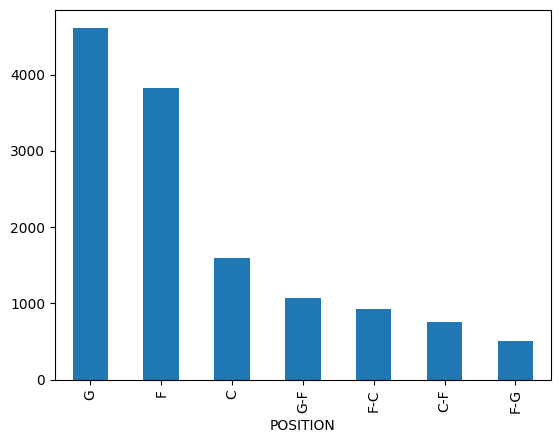

In [ ]:
nba_df["POSITION"].value_counts().plot(kind="bar")

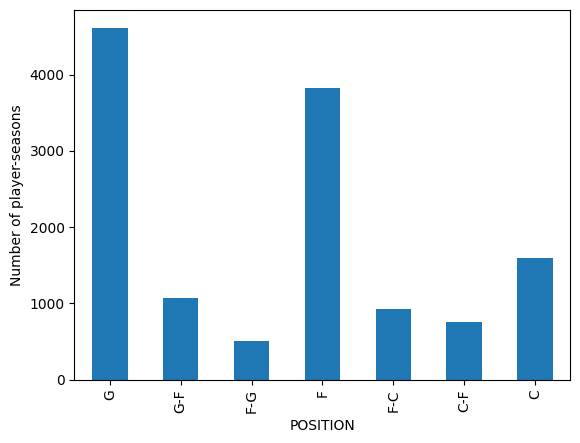

In [ ]:
#Reorder bar chart based on the perimeter-to-interior ordering that basketball players typically assume in their positions on court
nba_df["POSITION"].value_counts().reindex(position_order).plot(kind="bar")
plt.ylabel("Number of player-seasons")
plt.show()

In [ ]:
#Proportion of players in each position

print(nba_df["POSITION"].value_counts(normalize=True).reindex(position_order).round(3))

POSITION
G      0.347
G-F    0.081
F-G    0.038
F      0.288
F-C    0.069
C-F    0.057
C      0.120
Name: proportion, dtype: float64


In [ ]:
#Target balancing, 5-number summary and measures of central tendency

print((nba_df.groupby("PLAYER_NAME")["POSITION"].nunique() > 1).sum(), "players have more than one position label")
print()
print(nba_df.groupby("PLAYER_NAME").size().describe())

0 players have more than one position label

count    2646.000000
mean        5.085412
std         4.247748
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max        22.000000
dtype: float64


EDA for Age/Games Played

In [ ]:
print(nba_df["AGE_rs"].unique())

[33. 34. 35. 36. 37. 23. 24. 25. 22. nan 19. 26. 27. 28. 29. 30. 31. 32.
 20. 21. 38. 39. 40. 18. 41. 42. 43. 44.]


In [ ]:
print(nba_df["AGE_rs"].value_counts().sort_index())

AGE_rs
18.0       3
19.0      77
20.0     319
21.0     536
22.0     818
23.0    1219
24.0    1333
25.0    1195
26.0    1057
27.0    1016
28.0     888
29.0     817
30.0     739
31.0     642
32.0     565
33.0     465
34.0     368
35.0     257
36.0     204
37.0     141
38.0      88
39.0      52
40.0      29
41.0       9
42.0       5
43.0       3
44.0       1
Name: count, dtype: int64


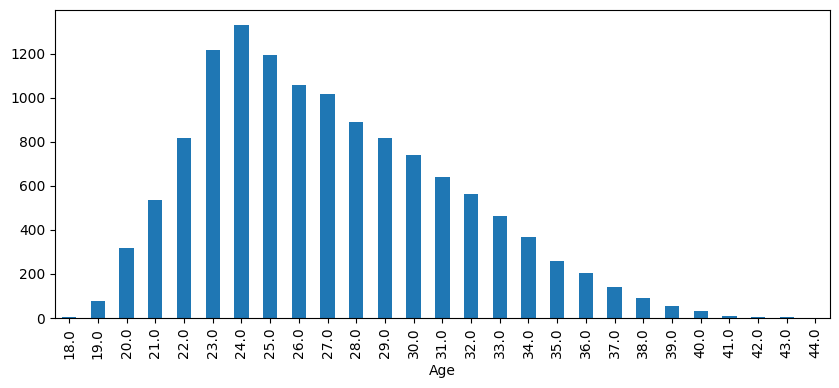

In [ ]:
nba_df["AGE_rs"].value_counts().sort_index().plot(kind="bar", figsize=(10, 4))
plt.xlabel("Age")
plt.show()

count    12846.000000
mean        51.148373
std         25.088969
min          1.000000
25%         31.000000
50%         57.000000
75%         73.000000
max         85.000000
Name: GP_rs, dtype: float64


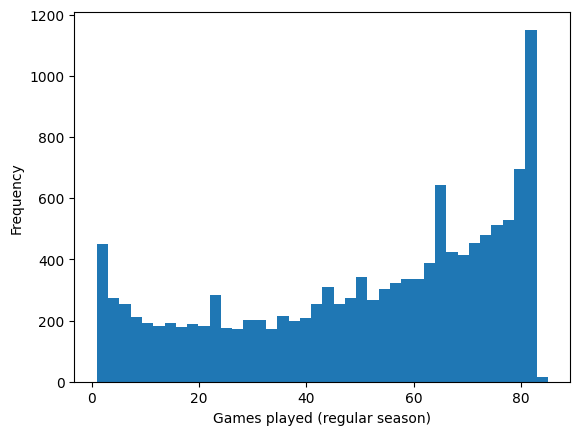

In [ ]:
print(nba_df["GP_rs"].describe())
nba_df["GP_rs"].plot.hist(bins=40)
plt.xlabel("Games played (regular season)")
plt.show()

Regular Per-Game Statistics

In [ ]:
print(nba_df[["MIN_rs", "FGA_rs", "FG3A_rs", "FTA_rs", "REB_rs", "AST_rs", "TOV_rs", "STL_rs", "BLK_rs", "PF_rs"]].describe())

             MIN_rs        FGA_rs       FG3A_rs        FTA_rs        REB_rs  \
count  12846.000000  12846.000000  12846.000000  12846.000000  12846.000000   
mean      20.218294      6.833092      1.766168      1.962082      3.557995   
std        9.985724      4.638539      1.894293      1.761945      2.477936   
min        0.100000      0.000000      0.000000      0.000000      0.000000   
25%       12.000000      3.200000      0.100000      0.800000      1.800000   
50%       19.600000      5.700000      1.200000      1.400000      3.000000   
75%       28.500000      9.500000      2.900000      2.600000      4.700000   
max       43.700000     27.800000     13.200000     13.100000     16.300000   

             AST_rs        TOV_rs        STL_rs        BLK_rs         PF_rs  
count  12846.000000  12846.000000  12846.000000  12846.000000  12846.000000  
mean       1.824467      1.168138      0.641196      0.408843      1.825627  
std        1.800772      0.798576      0.441368      0

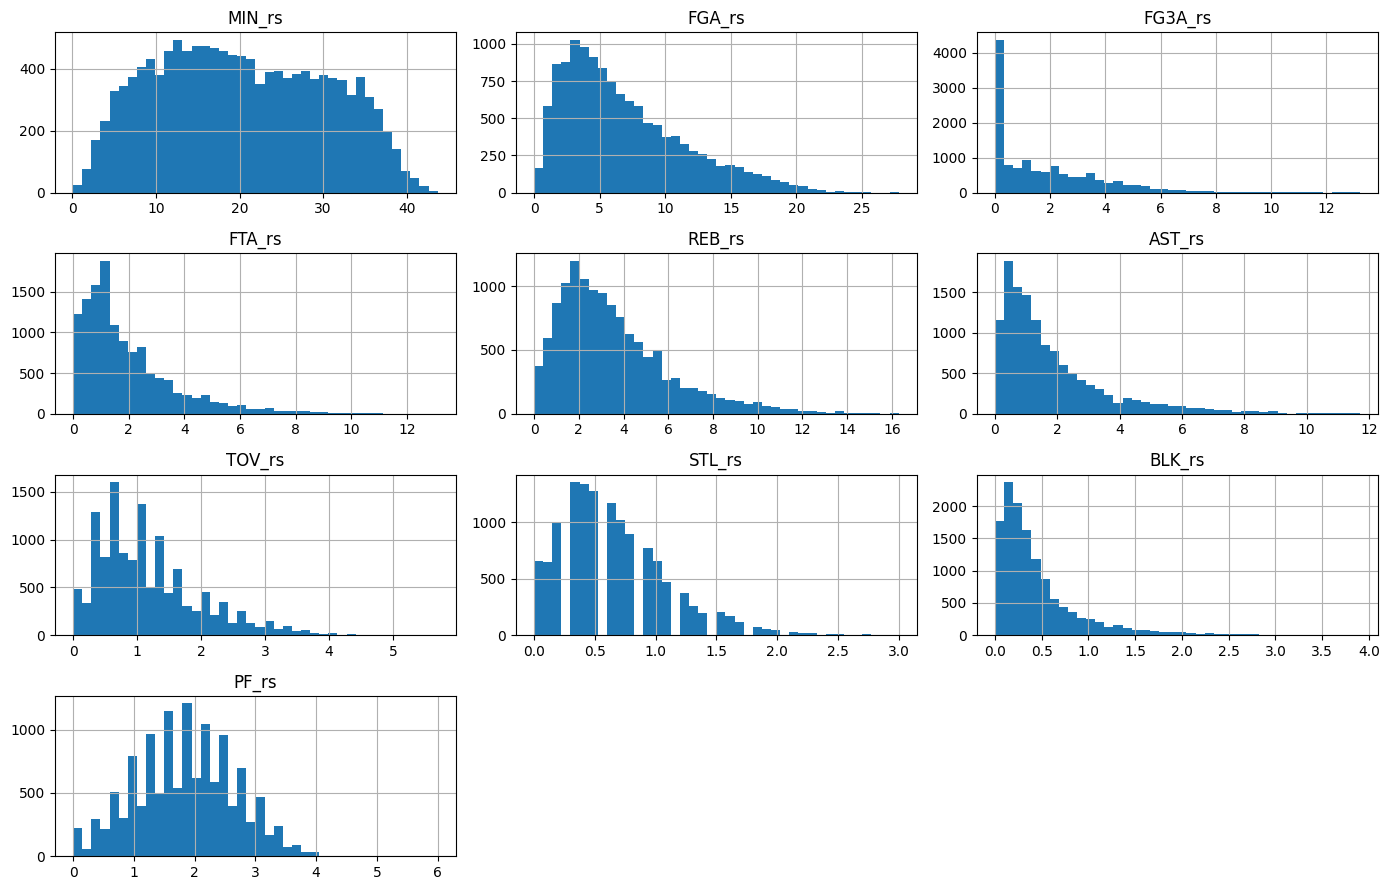

In [ ]:
nba_df[["MIN_rs", "FGA_rs", "FG3A_rs", "FTA_rs", "REB_rs", "AST_rs", "TOV_rs", "STL_rs", "BLK_rs", "PF_rs"]].hist(bins=40, figsize=(14, 9))
plt.tight_layout()
plt.show()

Season total (Possessions, Touches) statistics

In [ ]:
print(nba_df[["MIN", "TOUCHES", "TIME_OF_POSS", "AVG_SEC_PER_TOUCH", "AVG_DRIB_PER_TOUCH", "PTS_PER_TOUCH", "POST_TOUCHES", "PAINT_TOUCHES", "ELBOW_TOUCHES"]].describe())

               MIN      TOUCHES  TIME_OF_POSS  AVG_SEC_PER_TOUCH  \
count  5309.000000  5309.000000   5309.000000        5309.000000   
mean   1086.332266  1855.377661     93.958486           2.677664   
std     815.008044  1589.849879    115.029730           1.304627   
min       1.000000     0.000000      0.000000           0.000000   
25%     310.000000   460.000000     16.100000           1.660000   
50%    1011.000000  1547.000000     52.900000           2.160000   
75%    1765.000000  2870.000000    120.500000           3.610000   
max    3125.000000  7782.000000    749.900000          24.840000   

       AVG_DRIB_PER_TOUCH  PTS_PER_TOUCH  POST_TOUCHES  PAINT_TOUCHES  \
count         5309.000000    5309.000000   5309.000000    5309.000000   
mean             1.877538       0.253489     43.150311     104.358825   
std              1.560114       0.100171    102.143611     143.585656   
min              0.000000       0.000000      0.000000       0.000000   
25%              0.610

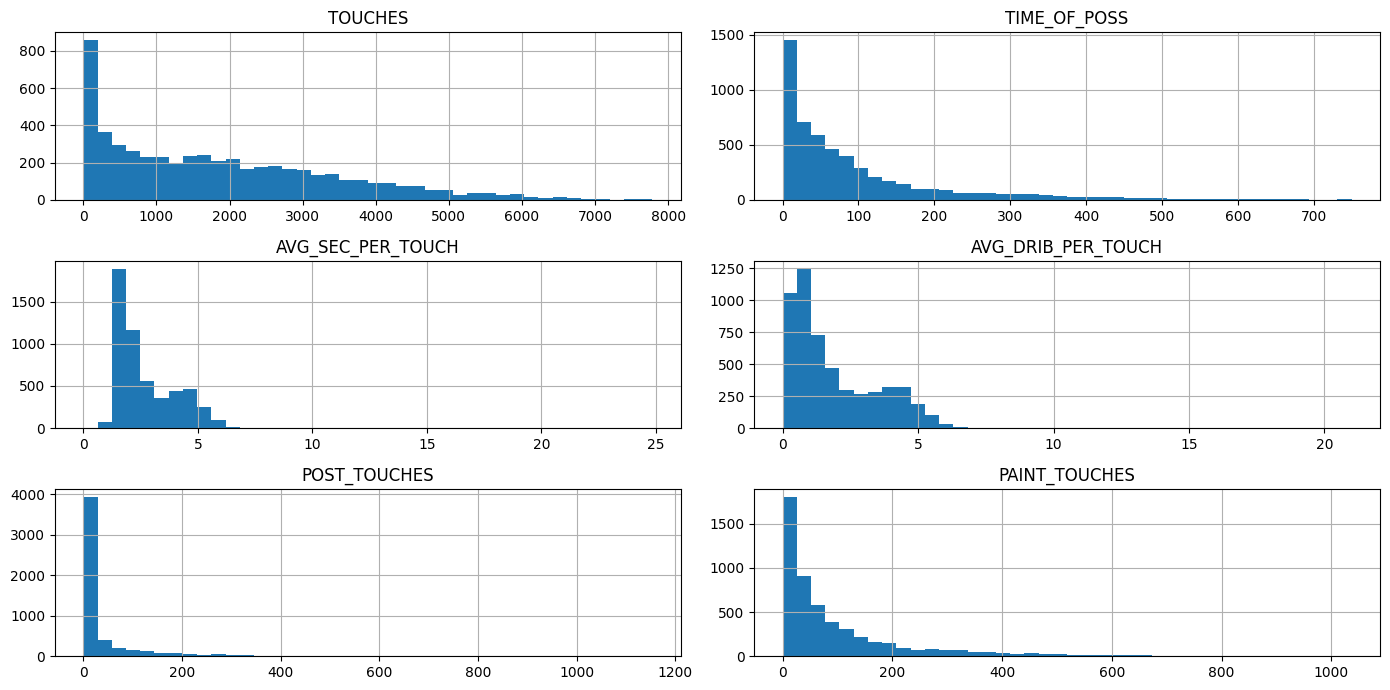

In [ ]:
nba_df[["TOUCHES", "TIME_OF_POSS", "AVG_SEC_PER_TOUCH", "AVG_DRIB_PER_TOUCH", "POST_TOUCHES", "PAINT_TOUCHES"]].hist(bins=40, figsize=(14, 7))
plt.tight_layout()
plt.show()

Creating a uniform scale (putting all players' performance as a per 12-minute scale)

In [ ]:
print(nba_df.loc[:, ["MIN_rs", "REB_rs"]].corr())
print(nba_df.loc[:, ["MIN_rs", "AST_rs"]].corr())
print(nba_df.loc[:, ["MIN_rs", "BLK_rs"]].corr())
print(nba_df.loc[:, ["MIN_rs", "FG3A_rs"]].corr())

          MIN_rs    REB_rs
MIN_rs  1.000000  0.687695
REB_rs  0.687695  1.000000
          MIN_rs    AST_rs
MIN_rs  1.000000  0.677556
AST_rs  0.677556  1.000000
         MIN_rs   BLK_rs
MIN_rs  1.00000  0.38346
BLK_rs  0.38346  1.00000
           MIN_rs   FG3A_rs
MIN_rs   1.000000  0.530149
FG3A_rs  0.530149  1.000000


In [ ]:
# Keep players who actually played (10+ minutes per game) and have a position, then convert to per-12-minute rates
eda_df = nba_df[(nba_df["MIN_rs"].notnull()) & (nba_df["MIN_rs"] >= 10) & (nba_df["POSITION"].notnull())].copy()

for stat in ["FGA", "FG3A", "FTA", "OREB", "DREB", "REB", "AST", "TOV", "STL", "BLK", "PF"]:
    eda_df[stat + "_p12"] = eda_df[stat + "_rs"] / eda_df["MIN_rs"] * 12

# 2-point attempts, total attempts minus 3-point attempts
eda_df["FG2A_p12"] = eda_df["FGA_p12"] - eda_df["FG3A_p12"]

# Era: before or after the three-point revolution
season_start = eda_df["SEASON"].str.split("-").str[0].astype(int)
eda_df["era"] = "pre-2014"
eda_df.loc[season_start >= 2014, "era"] = "2014+"
era_order = ["pre-2014", "2014+"]

print(eda_df.shape)

(10443, 166)


In [ ]:
print(eda_df.loc[:, ["MIN_rs", "REB_p12"]].corr())
print(eda_df.loc[:, ["MIN_rs", "AST_p12"]].corr())
print(eda_df.loc[:, ["MIN_rs", "BLK_p12"]].corr())
print(eda_df.loc[:, ["MIN_rs", "FG3A_p12"]].corr())

           MIN_rs   REB_p12
MIN_rs   1.000000 -0.026653
REB_p12 -0.026653  1.000000
           MIN_rs   AST_p12
MIN_rs   1.000000  0.278019
AST_p12  0.278019  1.000000
           MIN_rs   BLK_p12
MIN_rs   1.000000 -0.057758
BLK_p12 -0.057758  1.000000
           MIN_rs  FG3A_p12
MIN_rs    1.00000   0.10165
FG3A_p12  0.10165   1.00000


Assists, rebounds, 3pt shots per 12 minutes by position

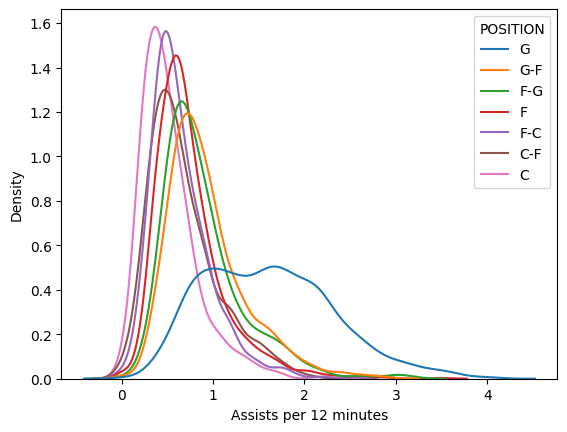

In [ ]:
sns.kdeplot(
    data=eda_df,
    x="AST_p12",
    hue="POSITION",
    hue_order=position_order,
    common_norm=False
)
plt.xlabel("Assists per 12 minutes")
plt.show()

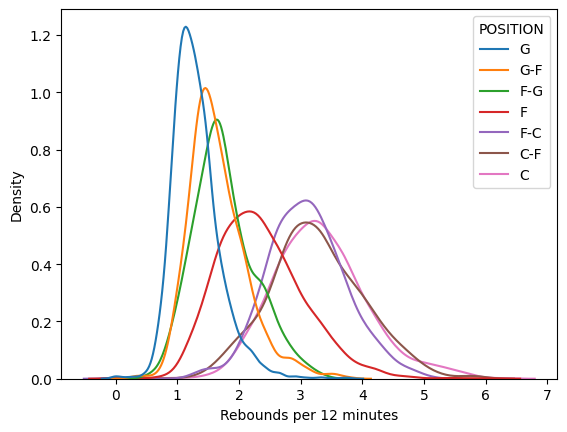

In [ ]:
sns.kdeplot(
    data=eda_df,
    x="REB_p12",
    hue="POSITION",
    hue_order=position_order,
    common_norm=False
)
plt.xlabel("Rebounds per 12 minutes")
plt.show()

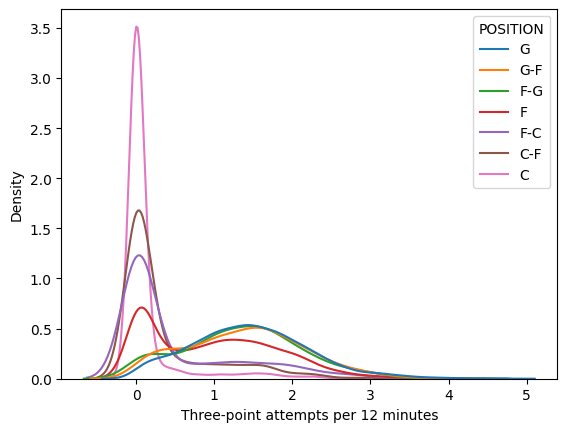

In [ ]:
sns.kdeplot(
    data=eda_df,
    x="FG3A_p12",
    hue="POSITION",
    hue_order=position_order,
    common_norm=False
)
plt.xlabel("Three-point attempts per 12 minutes")
plt.show()

Bivariate Distribution (Relationship between assists and rebounds, assists and turnovers)

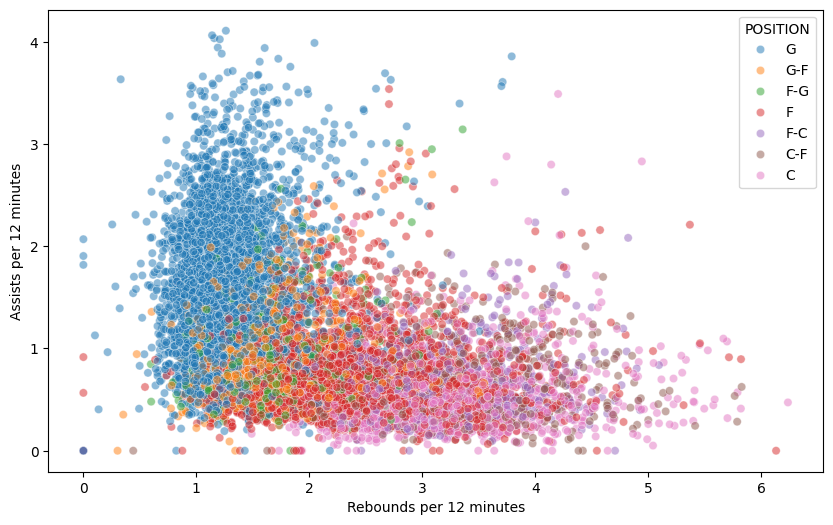

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=eda_df,
    x="REB_p12",
    y="AST_p12",
    hue="POSITION",
    hue_order=position_order,
    alpha=0.5
)
plt.xlabel("Rebounds per 12 minutes")
plt.ylabel("Assists per 12 minutes")
plt.show()

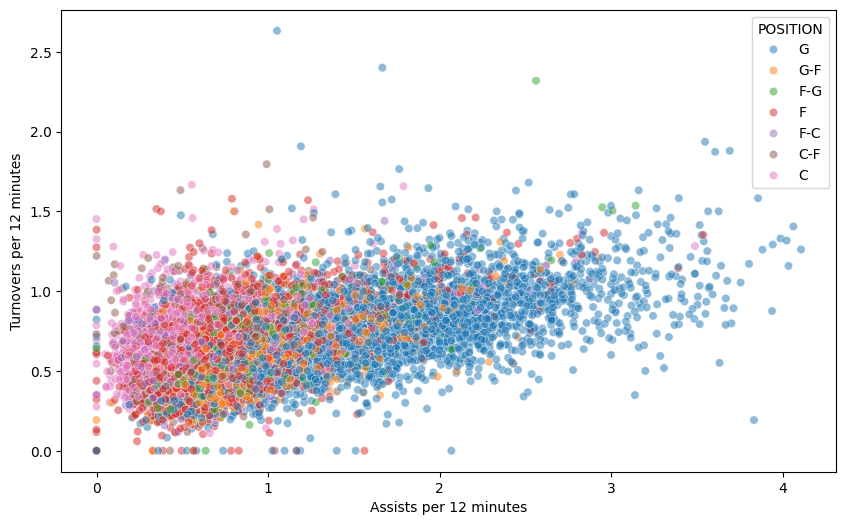

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=eda_df,
    x="AST_p12",
    y="TOV_p12",
    hue="POSITION",
    hue_order=position_order,
    alpha=0.5
)
plt.xlabel("Assists per 12 minutes")
plt.ylabel("Turnovers per 12 minutes")
plt.show()